# Análise e agrupamento de eventos cibernéticos com a CEDB

**Projeto:** Governança de Dados e Ciência de Dados — UEL  
**Fonte:** Cyber Events Database (CEDB)  
**Abordagem:** análise exploratória + agrupamento (clustering) + preparação de indicadores para Power BI.

## Objetivo

Este notebook utiliza a CEDB para identificar **perfis de eventos cibernéticos semelhantes**. A ideia é organizar os registros em grupos que ajudem uma equipe de segurança a investigar padrões, comparar contextos e decidir quais eventos merecem análise mais aprofundada.

> **Limite importante:** clustering encontra semelhanças; ele não determina sozinho a gravidade nem a prioridade de um incidente. A CEDB é uma base de eventos divulgados publicamente e não representa, necessariamente, todos os incidentes. A priorização final depende de critérios de negócio e de informações internas da organização.

## Etapas

1. Carregar e validar a CEDB.
2. Analisar qualidade e ausência de dados.
3. Preparar as variáveis adequadas para agrupamento.
4. Comparar diferentes quantidades de grupos.
5. Interpretar os perfis encontrados.
6. Criar indicadores de apoio à triagem — sem inventar uma nota de risco.
7. Exportar tabelas para construção de um dashboard no Power BI.
8. Documentar riscos, limitações e monitoramento.

## 0. Preparação do ambiente

O notebook utiliza bibliotecas comuns de análise de dados e o algoritmo K-Means. Se estiver no Google Colab, execute a instalação abaixo caso alguma biblioteca esteja ausente.

In [8]:
%pip -q install pandas numpy matplotlib seaborn scikit-learn

In [9]:
import os
import json
import hashlib
import warnings
from datetime import datetime

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from IPython.display import display, Markdown
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score

warnings.filterwarnings("ignore")
pd.set_option("display.max_columns", 100)
pd.set_option("display.max_colwidth", 100)

SEMENTE = 42
PASTA_SAIDA = "resultados_cedb"
os.makedirs(PASTA_SAIDA, exist_ok=True)

print("Ambiente preparado.")

Ambiente preparado.


## 1. Carregamento da base CEDB

Envie o arquivo tratado utilizado nas etapas anteriores (`cyber_events_tratado.csv`). O notebook também aceita outro nome de arquivo CSV, desde que seja a mesma base CEDB e contenha as colunas necessárias para a análise.

In [10]:
from pathlib import Path

ARQUIVO = "cyber_events_tratado.csv"

if not Path(ARQUIVO).exists():
    try:
        from google.colab import files
        enviados = files.upload()
        if enviados:
            ARQUIVO = next(iter(enviados))
    except Exception:
        pass

if not Path(ARQUIVO).exists():
    raise FileNotFoundError(
        "Arquivo CSV não encontrado. Coloque cyber_events_tratado.csv "
        "na pasta do notebook ou faça upload no Colab."
    )

df_original = pd.read_csv(ARQUIVO, low_memory=False)
df = df_original.copy()
df.columns = [str(c).strip() for c in df.columns]

with open(ARQUIVO, "rb") as f:
    HASH_DADOS = hashlib.sha256(f.read()).hexdigest()

print(f"Arquivo: {ARQUIVO}")
print(f"SHA-256: {HASH_DADOS}")
print(f"Dimensões: {df.shape[0]:,} registros x {df.shape[1]} colunas")
display(df.head())

Arquivo: cyber_events_tratado.csv
SHA-256: 5a132adcd0892bd1431b3439117e7f064572ee86de91f25d652742967bee4cb4
Dimensões: 17,476 registros x 20 colunas


,slug,event_date,year,month,actor,actor_type,organization,industry,motive,event_type,event_subtype,magnitude,duration,scope,org_data,cust_data,description,source_url,country,actor_country
0,lbe7q3joumwmx0o0,2026-08-31,2026,8,FulcrumSec,Criminal,Manchester Airports Group,Transportation and Warehousing,Financial,Exploitive,Exploitation of Application Server,NaN,NaN,NaN,None reported,"8.7 million customers; email addresses, phone numbers, vehicle registration numbers, postcodes; ...",FulcrumSec claimed it accessed Manchester Airports Group customer information using exposed Iter...,https://hackread.com/fulcrumsec-hackers-manchester-airports-data-breach,United Kingdom of Great Britain and Northern Ireland,Undetermined
1,c6L9dF2gJ4kM8qR3,2026-08-31,2026,8,Aurora,Criminal,Undisclosed consumer-goods or luxury organization,Undetermined,Financial,Exploitive,Undetermined,NaN,NaN,NaN,Wildcard TLS certificate private key and other organizational data exfiltrated; exact quantity u...,None reported,An Aurora affiliate stole a wildcard TLS certificate private key and other data from an unnamed ...,https://thehackernews.com/2026/08/aurora-ransomware-operators-use-cursor.html,Undetermined,Undetermined
2,f7K2mQ9vR4xT8bN1,2026-08-31,2026,8,Undetermined,Criminal,Undisclosed Claude user,Undetermined,Financial,Exploitive,Exploitation of End Hosts,NaN,NaN,NaN,Active Claude login session token and browser authentication data stolen from the victim's infec...,None reported,A criminal operator used commodity infostealer malware on an affected user's computer to steal a...,https://thecyberexpress.com/infostealers-hijacking-claude-sessions,Undetermined,Undetermined
3,z6H3cR9wP2mF8xV4,2026-08-31,2026,8,Fire Ant,Nation-State,Undisclosed organization investigated by Sygnia,Undetermined,Political-Espionage,Exploitive,Exploitation of Network Infrastructure,NaN,NaN,NaN,Network traffic and administrative credentials captured from compromised Cisco IOS XR routers an...,None reported,"Fire Ant compromised Cisco IOS XR routers, TACACS authentication systems, and Linux management h...",https://industrialcyber.co/threats-attacks/sygnia-highlights-fire-ant-risks-from-compromised-rou...,Undetermined,China
4,d6H3kM9rV2pF8cQ5,2026-08-27,2026,8,Undetermined,Criminal,City of Circleville,Public Administration,Financial,Disruptive,Data Attack,Affected municipal systems were isolated and rebuilt from clean environments or recovered throug...,Undetermined; City operations had been restored by August 26,Portions of the City's technology environment; exact systems and number of devices undisclosed,NaN,NaN,The City of Circleville confirmed ransomware activity affecting portions of its municipal techno...,https://dysruptionhub.com/circleville-ransomware-systems-restored,United States of America,Undetermined


## 2. Conhecendo e validando os dados

A análise não deve assumir que todas as colunas estão preenchidas. Primeiro verificamos a estrutura da base, os tipos de dados, possíveis duplicatas e o percentual de valores ausentes.

A coluna `event_type` descreve o efeito do evento (por exemplo, `Disruptive`, `Exploitive` e `Mixed`). Ela será usada para **descrever os grupos depois do clustering**, mas não será usada para formar os grupos. Assim evitamos que o algoritmo simplesmente reproduza essa classificação.

In [11]:
print("Colunas disponíveis:")
print(df.columns.tolist())

colunas_esperadas = ["year", "month"]
faltantes = [c for c in colunas_esperadas if c not in df.columns]
if faltantes:
    raise ValueError(f"A base não contém as colunas esperadas: {faltantes}")

# Conversão de ano e mês para formato numérico, quando possível
for col in ["year", "month", "duration", "magnitude", "scope"]:
    if col in df.columns:
        df[col] = pd.to_numeric(df[col], errors="coerce")

# Verificações gerais
resumo_validacao = pd.DataFrame([
    ["Base não vazia", len(df) > 0, f"{len(df)} registros"],
    ["Coluna year disponível", "year" in df.columns, "Necessária para análise temporal"],
    ["Coluna month disponível", "month" in df.columns, "Necessária para análise temporal"],
    ["Identificador slug disponível", "slug" in df.columns, "Útil para rastrear registros"],
    ["event_type disponível", "event_type" in df.columns, "Usada apenas na interpretação posterior"],
], columns=["verificacao", "resultado", "detalhe"])
display(resumo_validacao)

if "slug" in df.columns:
    print("Duplicatas de slug:", int(df["slug"].duplicated().sum()))

Colunas disponíveis:
['slug', 'event_date', 'year', 'month', 'actor', 'actor_type', 'organization', 'industry', 'motive', 'event_type', 'event_subtype', 'magnitude', 'duration', 'scope', 'org_data', 'cust_data', 'description', 'source_url', 'country', 'actor_country']


,verificacao,resultado,detalhe
0,Base não vazia,True,17476 registros
1,Coluna year disponível,True,Necessária para análise temporal
2,Coluna month disponível,True,Necessária para análise temporal
3,Identificador slug disponível,True,Útil para rastrear registros
4,event_type disponível,True,Usada apenas na interpretação posterior


Duplicatas de slug: 0


,coluna,tipo,valores_distintos,nulos,percentual_nulos
12,duration,float64,0,17476,100.00
13,scope,float64,0,17476,100.00
11,magnitude,float64,0,17476,100.00
14,org_data,object,1057,15382,88.02
15,cust_data,object,1290,15360,87.89
17,source_url,object,14382,4,0.02
16,description,object,15578,1,0.01
19,actor_country,object,91,1,0.01
3,month,int64,12,0,0.00
2,year,int64,13,0,0.00


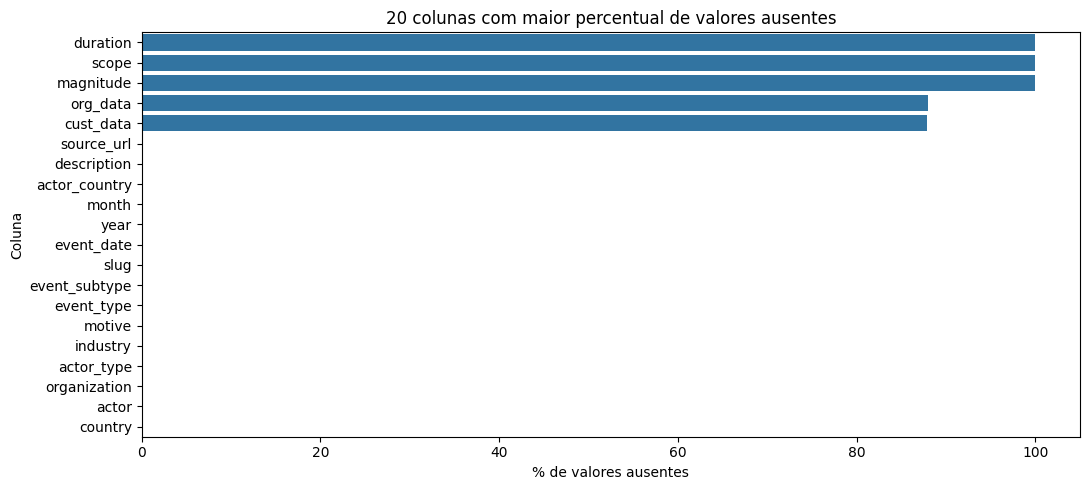

In [5]:
qualidade = pd.DataFrame({
    "coluna": df.columns,
    "tipo": [str(df[c].dtype) for c in df.columns],
    "valores_distintos": [df[c].nunique(dropna=True) for c in df.columns],
    "nulos": [int(df[c].isna().sum()) for c in df.columns],
    "percentual_nulos": [round(df[c].isna().mean() * 100, 2) for c in df.columns]
}).sort_values("percentual_nulos", ascending=False)

display(qualidade)
qualidade.to_csv(f"{PASTA_SAIDA}/qualidade_dados.csv", index=False, encoding="utf-8-sig")

plt.figure(figsize=(11, 5))
sns.barplot(data=qualidade.head(20), x="percentual_nulos", y="coluna")
plt.title("20 colunas com maior percentual de valores ausentes")
plt.xlabel("% de valores ausentes")
plt.ylabel("Coluna")
plt.tight_layout()
plt.show()

### 2.1 Decisão sobre os valores ausentes

Campos como `duration`, `magnitude` e `scope` podem ser úteis para avaliar impacto, mas a análise anterior da CEDB indicou ausência muito elevada nesses atributos. Por isso, o notebook **não os considera automaticamente**: eles só entram no agrupamento se tiverem preenchimento suficiente.

O limite abaixo é uma decisão técnica inicial para evitar que uma variável quase vazia influencie o resultado. Ele pode ser alterado, mas a justificativa deve ser registrada.

In [6]:
LIMITE_NULOS_FEATURE = 0.50  # usar somente colunas com até 50% de valores ausentes

CATEGORICAS_CANDIDATAS = [
    "actor_type", "industry", "motive", "country", "actor_country"
]
NUMERICAS_CANDIDATAS = ["duration", "magnitude", "scope"]

candidatas = [c for c in CATEGORICAS_CANDIDATAS + NUMERICAS_CANDIDATAS if c in df.columns]
elegibilidade = pd.DataFrame({
    "coluna": candidatas,
    "tipo": ["categórica" if c in CATEGORICAS_CANDIDATAS else "numérica" for c in candidatas],
    "percentual_nulos": [df[c].isna().mean() * 100 for c in candidatas]
})
elegibilidade["incluida"] = elegibilidade["percentual_nulos"] <= LIMITE_NULOS_FEATURE * 100
display(elegibilidade)

FEATURES_CATEGORICAS = elegibilidade.query(
    "tipo == 'categórica' and incluida"
)["coluna"].tolist()
FEATURES_NUMERICAS = elegibilidade.query(
    "tipo == 'numérica' and incluida"
)["coluna"].tolist()
FEATURES_CLUSTER = FEATURES_CATEGORICAS + FEATURES_NUMERICAS

if len(FEATURES_CLUSTER) < 2:
    raise ValueError(
        "Há menos de duas variáveis elegíveis para clustering. "
        "Revise a qualidade da base e o limite de valores ausentes."
    )

print("Variáveis categóricas:", FEATURES_CATEGORICAS)
print("Variáveis numéricas:", FEATURES_NUMERICAS)
print("Variáveis usadas no agrupamento:", FEATURES_CLUSTER)

,coluna,tipo,percentual_nulos,incluida
0,actor_type,categórica,0.000000,True
1,industry,categórica,0.000000,True
2,motive,categórica,0.000000,True
3,country,categórica,0.000000,True
4,actor_country,categórica,0.005722,True
5,duration,numérica,100.000000,False
6,magnitude,numérica,100.000000,False
7,scope,numérica,100.000000,False


Variáveis categóricas: ['actor_type', 'industry', 'motive', 'country', 'actor_country']
Variáveis numéricas: []
Variáveis usadas no agrupamento: ['actor_type', 'industry', 'motive', 'country', 'actor_country']


## 3. Preparação das variáveis para o clustering

O K-Means trabalha com valores numéricos. Por isso:

- variáveis categóricas são transformadas em indicadores numéricos (*One-Hot Encoding*);
- variáveis numéricas recebem preenchimento pela mediana e padronização;
- registros sem informação em uma variável categórica recebem a categoria `Não informado`.

Não utilizamos `slug`, nomes de organizações, descrição textual, IP ou `event_type` para formar os grupos. Isso evita usar identificadores, dados potencialmente sensíveis ou o próprio rótulo que será analisado depois.

In [13]:
# Cópia exclusiva das variáveis selecionadas
X = df[FEATURES_CLUSTER].copy()

for col in FEATURES_CATEGORICAS:
    X[col] = X[col].astype("string").str.strip()
    X[col] = X[col].replace("", pd.NA)

    # Converte os valores ausentes de pd.NA para np.nan
    X[col] = X[col].astype(object)
    X[col] = X[col].where(pd.notna(X[col]), np.nan)

transformadores = []

if FEATURES_CATEGORICAS:
    pipeline_cat = Pipeline(steps=[
        ("imputacao", SimpleImputer(strategy="constant", fill_value="Não informado")),
        ("codificacao", OneHotEncoder(
            handle_unknown="ignore",
            min_frequency=10,
            max_categories=30
        ))
    ])
    transformadores.append(("categoricas", pipeline_cat, FEATURES_CATEGORICAS))

if FEATURES_NUMERICAS:
    pipeline_num = Pipeline(steps=[
        ("imputacao", SimpleImputer(strategy="median")),
        ("padronizacao", StandardScaler())
    ])
    transformadores.append(("numericas", pipeline_num, FEATURES_NUMERICAS))

preprocessador = ColumnTransformer(transformers=transformadores)
X_transformado = preprocessador.fit_transform(X)

print("Matriz preparada:", X_transformado.shape)
print("Número de eventos:", X.shape[0])

Matriz preparada: (17476, 102)
Número de eventos: 17476


## 4. Escolha da quantidade de grupos

Não existe um número de clusters universalmente correto. Vamos testar diferentes valores de `k` e observar:

- **Inércia:** mede a distância dos registros aos centros dos grupos; tende a diminuir quando aumentamos o número de grupos.
- **Silhouette:** indica o quanto os registros estão próximos do próprio grupo e afastados dos demais. Valores maiores costumam indicar grupos mais separados.

Essas métricas ajudam na escolha, mas a decisão final também considera se os grupos são compreensíveis e úteis para a análise de segurança.

In [14]:
# A avaliação por silhouette usa uma amostra para manter o processamento viável.
MAX_AMOSTRA_SILHOUETTE = min(3000, X_transformado.shape[0])
ks = range(2, 9)
resultados_k = []

for k in ks:
    modelo_teste = KMeans(n_clusters=k, random_state=SEMENTE, n_init=10)
    rotulos_teste = modelo_teste.fit_predict(X_transformado)

    if len(np.unique(rotulos_teste)) > 1:
        sil = silhouette_score(
            X_transformado,
            rotulos_teste,
            sample_size=MAX_AMOSTRA_SILHOUETTE,
            random_state=SEMENTE
        )
    else:
        sil = np.nan

    resultados_k.append({
        "k": k,
        "inercia": modelo_teste.inertia_,
        "silhouette": sil
    })

avaliacao_k = pd.DataFrame(resultados_k)
display(avaliacao_k)

,k,inercia,silhouette
0,2,44894.228672,0.256000
1,3,40168.118785,0.203581
2,4,37336.676598,0.164153
3,5,35818.125621,0.123744
4,6,33339.131558,0.183786
5,7,32087.186434,0.191773
6,8,31465.771730,0.181641


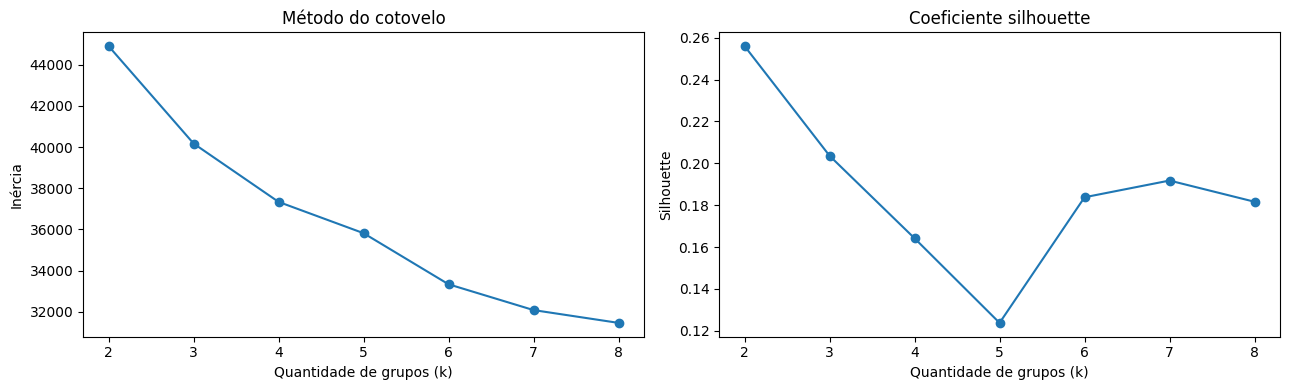

In [15]:
fig, ax = plt.subplots(1, 2, figsize=(13, 4))

ax[0].plot(avaliacao_k["k"], avaliacao_k["inercia"], marker="o")
ax[0].set_title("Método do cotovelo")
ax[0].set_xlabel("Quantidade de grupos (k)")
ax[0].set_ylabel("Inércia")

ax[1].plot(avaliacao_k["k"], avaliacao_k["silhouette"], marker="o")
ax[1].set_title("Coeficiente silhouette")
ax[1].set_xlabel("Quantidade de grupos (k)")
ax[1].set_ylabel("Silhouette")

plt.tight_layout()
plt.show()

### 4.1 Definição do número de grupos

O notebook sugere o `k` com maior silhouette, mas permite que a equipe escolha outro valor após analisar os gráficos e a interpretabilidade dos perfis. Registre a justificativa: por exemplo, grupos muito pequenos ou difíceis de explicar podem não ser úteis para o dashboard.

In [16]:
K_SUGERIDO = int(avaliacao_k.loc[avaliacao_k["silhouette"].idxmax(), "k"])
print("k sugerido pela maior silhouette:", K_SUGERIDO)

# Ajuste este valor se a interpretação dos grupos justificar outra escolha.
K_ESCOLHIDO = K_SUGERIDO

modelo_clusters = KMeans(
    n_clusters=K_ESCOLHIDO,
    random_state=SEMENTE,
    n_init=20
)
df["cluster_id"] = modelo_clusters.fit_predict(X_transformado)

print("Agrupamento concluído.")
display(df["cluster_id"].value_counts().sort_index().rename("quantidade_eventos").to_frame())

k sugerido pela maior silhouette: 2
Agrupamento concluído.


,quantidade_eventos
cluster_id,
0,12829
1,4647


## 5. Interpretação dos grupos encontrados

O número do cluster é apenas um identificador técnico. Cluster 0 não significa risco baixo, e cluster 1 não significa risco alto. Para interpretar cada grupo, vamos observar as categorias mais frequentes e as características numéricas disponíveis.

In [17]:
def moda_segura(serie):
    serie = serie.dropna().astype(str)
    if serie.empty:
        return "Sem informação"
    return serie.value_counts().index[0]

perfis = []
for cluster in sorted(df["cluster_id"].unique()):
    parte = df[df["cluster_id"] == cluster]
    linha = {
        "cluster_id": int(cluster),
        "quantidade_eventos": len(parte),
        "percentual_base": round(len(parte) / len(df) * 100, 2),
    }
    for col in FEATURES_CATEGORICAS:
        linha[f"mais_frequente_{col}"] = moda_segura(parte[col])
    for col in FEATURES_NUMERICAS:
        linha[f"mediana_{col}"] = parte[col].median()
    if "year" in parte.columns:
        linha["ano_mediano"] = parte["year"].median()
    perfis.append(linha)

perfil_clusters = pd.DataFrame(perfis)
display(perfil_clusters)
perfil_clusters.to_csv(
    f"{PASTA_SAIDA}/perfil_clusters.csv",
    index=False,
    encoding="utf-8-sig"
)

,cluster_id,quantidade_eventos,percentual_base,mais_frequente_actor_type,mais_frequente_industry,mais_frequente_motive,mais_frequente_country,mais_frequente_actor_country,ano_mediano
0,0,12829,73.41,Criminal,Health Care and Social Assistance,Financial,United States of America,Undetermined,2022.0
1,1,4647,26.59,Hacktivist,Public Administration,Protest,United States of America,Undetermined,2022.0


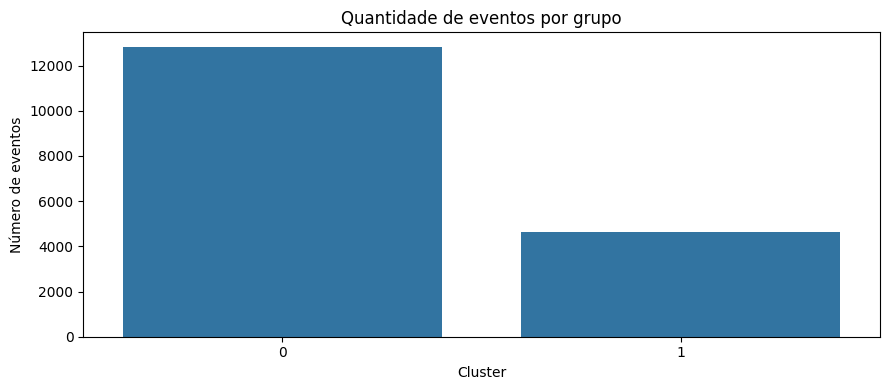

In [18]:
plt.figure(figsize=(9, 4))
ordem = df["cluster_id"].value_counts().sort_index()
sns.barplot(x=ordem.index.astype(str), y=ordem.values)
plt.title("Quantidade de eventos por grupo")
plt.xlabel("Cluster")
plt.ylabel("Número de eventos")
plt.tight_layout()
plt.show()

### Distribuição de **actor_type** por cluster

actor_type,Criminal,Hacktivist,Nation-State,Undetermined,Hobbyist,Terrorist,Language Model,Nation-state
cluster_id,,,,,,,,
0,99.6,0.0,0.0,0.2,0.1,0.0,0.0,0.0
1,1.3,47.1,27.1,19.2,4.5,0.7,0.1,0.0


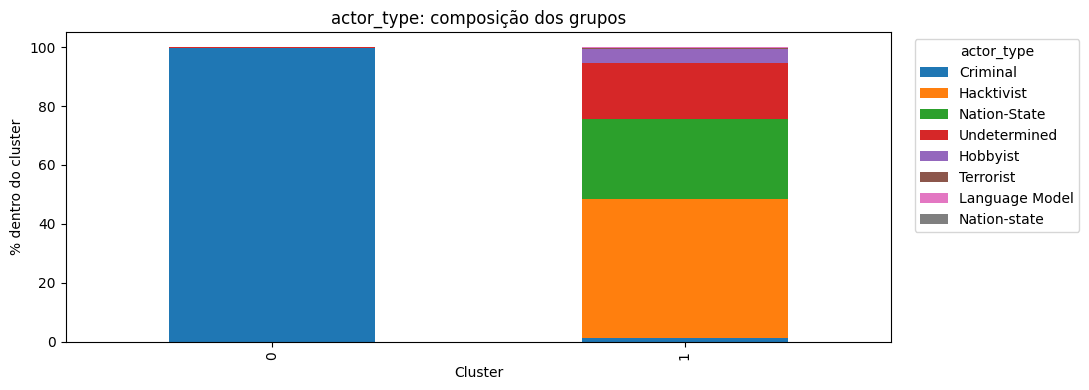

### Distribuição de **industry** por cluster

industry,Public Administration,Health Care and Social Assistance,Information,Finance and Insurance,Educational Services,"Professional, Scientific, and Technical Services",Other Services (except Public Administration),Manufacturing
cluster_id,,,,,,,,
0,13.2,17.3,9.4,10.4,10.2,9.2,5.1,5.4
1,35.6,2.5,15.9,7.1,4.6,4.3,6.9,3.6


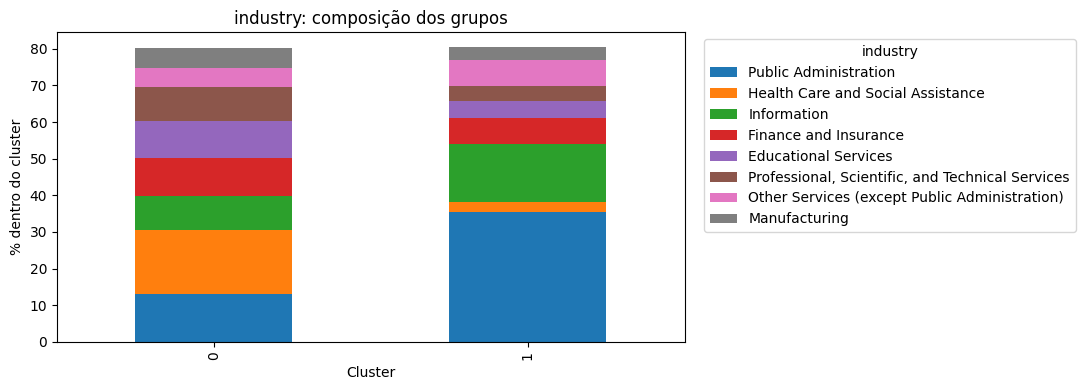

### Distribuição de **motive** por cluster

motive,Financial,Undetermined,Protest,Political-Espionage,Sabotage,Industrial-Espionage,Personal Attack,Political-espionage
cluster_id,,,,,,,,
0,78.3,17.1,0.8,1.9,0.9,0.3,0.6,0.0
1,2.8,30.9,39.8,15.6,7.7,1.6,0.4,0.6


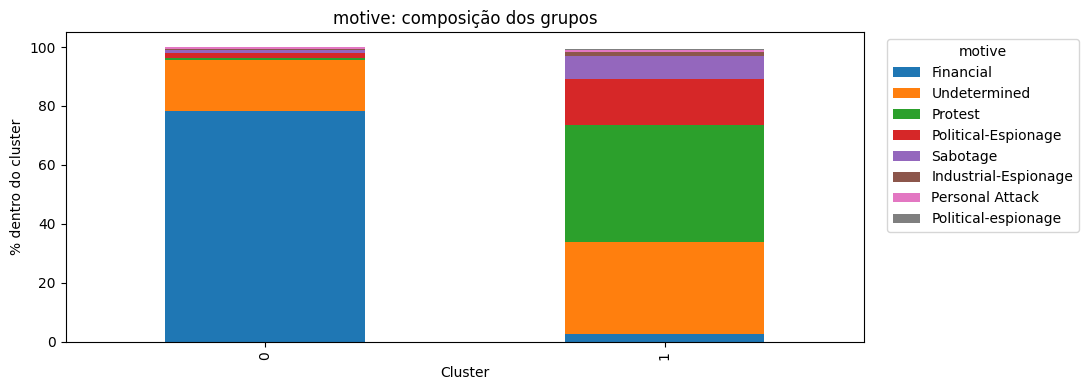

### Distribuição de **country** por cluster

country,United States of America,United Kingdom of Great Britain and Northern Ireland,Undetermined,Russian Federation,Italy,Ukraine,Canada,India
cluster_id,,,,,,,,
0,57.3,5.6,3.4,0.9,2.5,0.7,2.9,1.8
1,19.3,3.3,4.5,8.3,3.2,7.8,1.4,3.6


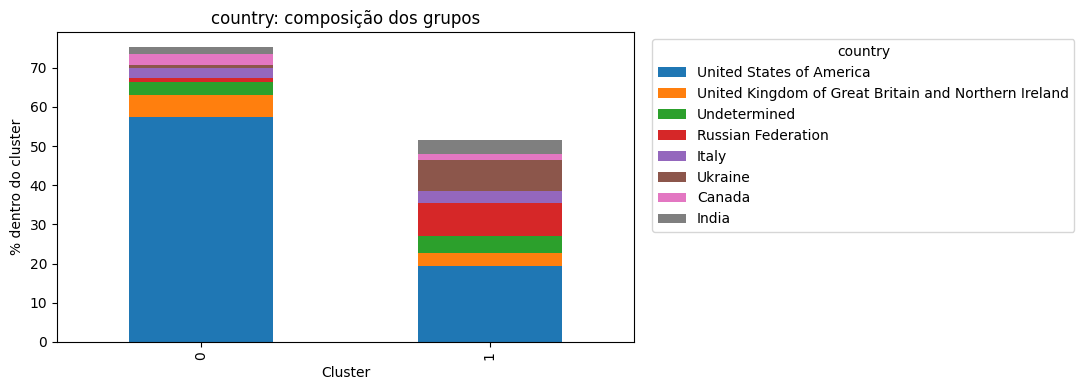

### Distribuição de **actor_country** por cluster

actor_country,Undetermined,Russian Federation,China,Korea (the Democratic People's Republic of),Ukraine,United States of America,Iran (Islamic Republic of),Saudi Arabia
cluster_id,,,,,,,,
0,91.1,7.6,0.1,0.0,0.0,0.2,0.2,0.0
1,36.7,23.0,6.1,4.2,3.8,3.0,2.8,1.8


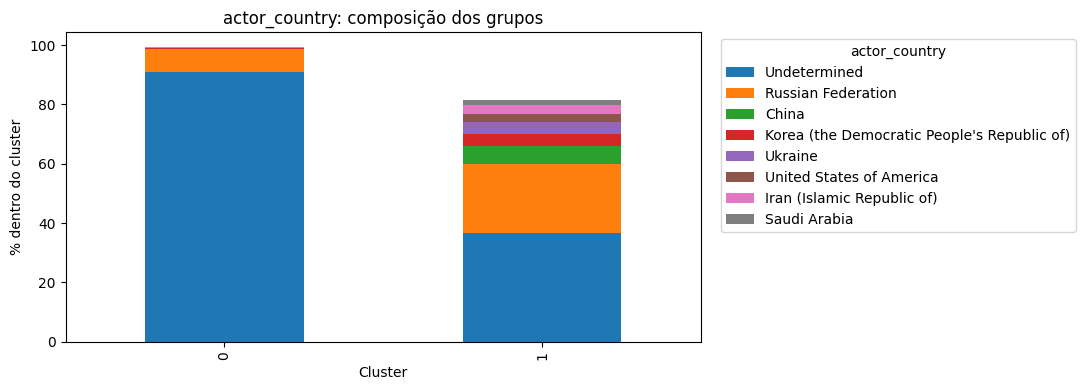

In [19]:
# Distribuição percentual das principais categorias dentro de cada cluster
for col in FEATURES_CATEGORICAS:
    tabela = pd.crosstab(df["cluster_id"], df[col], normalize="index") * 100
    top_categorias = df[col].value_counts().head(8).index
    tabela = tabela.reindex(columns=top_categorias, fill_value=0)

    display(Markdown(f"### Distribuição de **{col}** por cluster"))
    display(tabela.round(1))

    ax = tabela.plot(kind="bar", stacked=True, figsize=(11, 4))
    ax.set_ylabel("% dentro do cluster")
    ax.set_xlabel("Cluster")
    ax.set_title(f"{col}: composição dos grupos")
    ax.legend(title=col, bbox_to_anchor=(1.02, 1), loc="upper left")
    plt.tight_layout()
    plt.show()

### 5.1 Relação dos clusters com `event_type`

Agora podemos cruzar os grupos com `event_type`. Essa coluna não participou do treinamento do clustering; portanto, a tabela serve para entender como os efeitos dos eventos se distribuem entre os perfis.

A presença de `Mixed`, `Disruptive` ou `Exploitive` em um cluster não define automaticamente sua gravidade. A interpretação deve considerar o significado do efeito e o contexto de cada evento.

event_type,Disruptive,Exploitive,Mixed,Undetermined
cluster_id,,,,
0,21.5,56.2,21.0,1.4
1,53.9,41.4,3.8,0.8


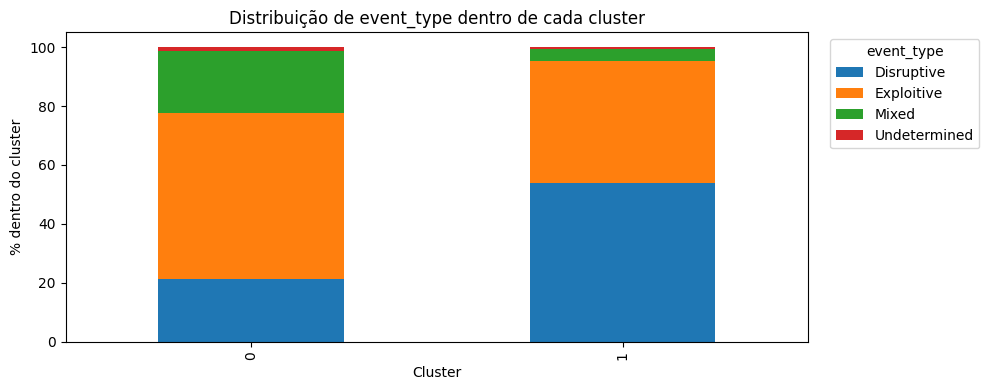

In [20]:
if "event_type" in df.columns:
    distribuicao_event_type = pd.crosstab(
        df["cluster_id"], df["event_type"], normalize="index"
    ) * 100
    display(distribuicao_event_type.round(1))

    ax = distribuicao_event_type.plot(
        kind="bar", stacked=True, figsize=(10, 4)
    )
    ax.set_title("Distribuição de event_type dentro de cada cluster")
    ax.set_xlabel("Cluster")
    ax.set_ylabel("% dentro do cluster")
    ax.legend(title="event_type", bbox_to_anchor=(1.02, 1), loc="upper left")
    plt.tight_layout()
    plt.show()
else:
    print("A coluna event_type não está disponível; etapa descritiva ignorada.")

## 6. Da análise à priorização: o que a CEDB permite afirmar?

Este projeto não vai atribuir uma nota automática de risco sem uma regra validada. A base contém contexto do evento, mas atributos diretamente ligados ao impacto — como duração, magnitude e abrangência — podem estar muito incompletos.

Em vez de criar pesos arbitrários, vamos gerar uma **matriz de disponibilidade de evidências**. Ela mostra quais informações existem e qual é a cobertura de cada uma. A equipe poderá usar essa avaliação para definir critérios de prioridade em uma etapa posterior, com participação de especialistas.

In [21]:
CAMPOS_POTENCIAIS_PRIORIZACAO = [
    "duration", "magnitude", "scope", "org_data", "cust_data",
    "event_type", "industry", "country", "year"
]

linhas = []
for col in CAMPOS_POTENCIAIS_PRIORIZACAO:
    if col in df.columns:
        linhas.append({
            "campo": col,
            "disponivel": True,
            "percentual_preenchido": round(df[col].notna().mean() * 100, 2),
            "valores_distintos": int(df[col].nunique(dropna=True)),
            "observacao": (
                "Possível evidência para avaliação; significado e qualidade precisam ser validados."
            )
        })
    else:
        linhas.append({
            "campo": col,
            "disponivel": False,
            "percentual_preenchido": 0,
            "valores_distintos": 0,
            "observacao": "Campo não encontrado nesta versão da CEDB."
        })

disponibilidade_priorizacao = pd.DataFrame(linhas)
display(disponibilidade_priorizacao)
disponibilidade_priorizacao.to_csv(
    f"{PASTA_SAIDA}/disponibilidade_campos_priorizacao.csv",
    index=False,
    encoding="utf-8-sig"
)

,campo,disponivel,percentual_preenchido,valores_distintos,observacao
0,duration,True,0.00,0,Possível evidência para avaliação; significado e qualidade precisam ser validados.
1,magnitude,True,0.00,0,Possível evidência para avaliação; significado e qualidade precisam ser validados.
2,scope,True,0.00,0,Possível evidência para avaliação; significado e qualidade precisam ser validados.
3,org_data,True,11.98,1057,Possível evidência para avaliação; significado e qualidade precisam ser validados.
4,cust_data,True,12.11,1290,Possível evidência para avaliação; significado e qualidade precisam ser validados.
5,event_type,True,100.00,4,Possível evidência para avaliação; significado e qualidade precisam ser validados.
6,industry,True,100.00,27,Possível evidência para avaliação; significado e qualidade precisam ser validados.
7,country,True,100.00,182,Possível evidência para avaliação; significado e qualidade precisam ser validados.
8,year,True,100.00,13,Possível evidência para avaliação; significado e qualidade precisam ser validados.


### 6.1 Proposta de critérios para validação com especialistas

A tabela abaixo é um **roteiro de decisão**, não uma pontuação implementada. Antes de criar um score, a equipe deve definir o significado operacional de cada critério, como medir, o que fazer quando faltar informação e quais pesos (se houver) são justificáveis.

| Critério a validar | Exemplo de pergunta para a equipe |
|---|---|
| Impacto operacional | O evento interrompeu serviços ou operações críticas? |
| Exposição de dados | Houve acesso, divulgação ou perda de dados sensíveis? |
| Abrangência | Quantas unidades, sistemas, clientes ou usuários foram afetados? |
| Duração | Por quanto tempo o impacto persistiu? |
| Criticidade do setor/ativo | O ativo atingido é essencial para a organização? |
| Recorrência | Há eventos semelhantes ou repetidos? |
| Confiança da informação | A evidência é confirmada, parcial ou apenas reportada publicamente? |

**Atenção:** `event_type` descreve o tipo de efeito, mas não substitui uma avaliação contextual de impacto. A CEDB também não informa necessariamente a criticidade dos ativos da empresa que utilizará o dashboard.

## 7. Preparação dos dados para o Power BI

Serão exportados arquivos CSV para construir um dashboard. A tabela de eventos contém o identificador do cluster e campos descritivos; a tabela de perfis resume cada grupo; e a tabela de disponibilidade mostra as limitações dos campos usados na discussão de prioridade.

Se a coluna `organization` existir, ela não será incluída na exportação padrão para reduzir exposição de nomes de vítimas. O campo `description` e identificadores técnicos como IP também não serão exportados.

In [22]:
# Seleciona somente campos úteis para análise e dashboard.
colunas_dashboard = []
for col in [
    "slug", "year", "month", "event_type", "actor_type", "industry",
    "motive", "country", "actor_country", "duration", "magnitude", "scope"
]:
    if col in df.columns:
        colunas_dashboard.append(col)

eventos_dashboard = df[colunas_dashboard + ["cluster_id"]].copy()

eventos_dashboard.to_csv(
    f"{PASTA_SAIDA}/eventos_com_clusters.csv",
    index=False,
    encoding="utf-8-sig"
)

perfil_clusters.to_csv(
    f"{PASTA_SAIDA}/perfil_clusters.csv",
    index=False,
    encoding="utf-8-sig"
)

disponibilidade_priorizacao.to_csv(
    f"{PASTA_SAIDA}/disponibilidade_campos_priorizacao.csv",
    index=False,
    encoding="utf-8-sig"
)

print("Arquivos exportados:")
for nome in sorted(os.listdir(PASTA_SAIDA)):
    print("-", nome)

Arquivos exportados:
- disponibilidade_campos_priorizacao.csv
- eventos_com_clusters.csv
- perfil_clusters.csv
- qualidade_dados.csv


### 7.1 Sugestão de páginas do dashboard

**Página 1 — Visão geral**
- Total de eventos;
- eventos por ano;
- distribuição por `event_type`;
- quantidade e percentual por cluster.

**Página 2 — Perfis de eventos**
- filtros por cluster, país, setor e período;
- características predominantes de cada grupo;
- distribuição de `event_type` por cluster.

**Página 3 — Apoio à priorização**
- disponibilidade de duração, magnitude e abrangência;
- eventos com informações mais completas;
- filtros para revisão humana;
- critérios de prioridade definidos pela organização, quando forem validados.

**Página 4 — Qualidade e governança**
- percentual de valores ausentes;
- período coberto;
- limitações da CEDB;
- data e hash da versão dos dados.

O dashboard deve deixar claro que os grupos são perfis estatísticos e não níveis de risco.

## 8. Monitoramento da solução analítica

Como não estamos implantando um modelo supervisionado, não faz sentido monitorar F1 ou acurácia. Para o clustering, o acompanhamento deve observar:
- mudanças na quantidade de eventos por grupo;
- alterações nos perfis predominantes;
- mudanças na distribuição de variáveis;
- aumento de valores ausentes;
- surgimento de categorias novas;
- mudanças na composição da base ao longo do tempo.

A comparação temporal abaixo é exploratória. Para uso recorrente, será necessário definir períodos de referência, limites de alerta e um procedimento de revisão dos clusters.

cluster_id,0,1
year,,
2014,55.0,45.0
2015,49.0,51.0
2016,52.4,47.6
2017,67.8,32.2
2018,85.0,15.0
2019,85.7,14.3
2020,87.0,13.0
2021,93.4,6.6
2022,68.8,31.2


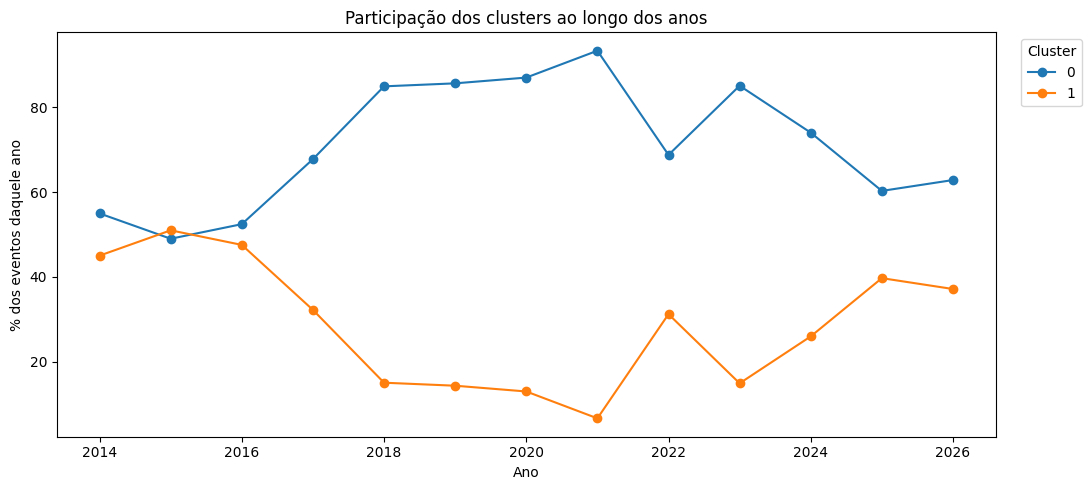

In [23]:
if "year" in df.columns:
    distribuicao_temporal = pd.crosstab(
        df["year"], df["cluster_id"], normalize="index"
    ) * 100
    display(distribuicao_temporal.round(1))

    ax = distribuicao_temporal.plot(
        kind="line", marker="o", figsize=(11, 5)
    )
    ax.set_title("Participação dos clusters ao longo dos anos")
    ax.set_xlabel("Ano")
    ax.set_ylabel("% dos eventos daquele ano")
    ax.legend(title="Cluster", bbox_to_anchor=(1.02, 1), loc="upper left")
    plt.tight_layout()
    plt.show()

    distribuicao_temporal.to_csv(
        f"{PASTA_SAIDA}/distribuicao_clusters_por_ano.csv",
        encoding="utf-8-sig"
    )
else:
    print("Coluna year indisponível; monitoramento temporal não executado.")

In [ ]:
# Relatório simples de qualidade para acompanhamento
monitoramento_qualidade = pd.DataFrame({
    "coluna": df.columns,
    "percentual_nulos_atual": (df.isna().mean() * 100).round(2),
    "valores_distintos_atual": df.nunique(dropna=True).values
})
monitoramento_qualidade.to_csv(
    f"{PASTA_SAIDA}/monitoramento_qualidade.csv",
    index=False,
    encoding="utf-8-sig"
)
display(monitoramento_qualidade.sort_values(
    "percentual_nulos_atual", ascending=False
).head(15))

## 9. Governança, riscos e limitações

### Riscos identificados
1. **Viés de divulgação:** a CEDB depende de eventos conhecidos e reportados publicamente; incidentes não divulgados podem não aparecer.
2. **Concentração geográfica:** países com maior cobertura de notícias podem aparecer mais na base.
3. **Dados ausentes:** campos relacionados a impacto podem ter baixa cobertura.
4. **Interpretação indevida dos clusters:** grupos não representam automaticamente níveis de severidade.
5. **Mudança ao longo do tempo:** padrões de registro e categorias podem mudar.
6. **Privacidade e minimização:** nomes de organizações, descrições e IPs não são necessários para o agrupamento inicial e devem ser tratados com cautela.

### Limitações da solução
- O resultado depende das variáveis selecionadas e do número de clusters.
- K-Means tende a favorecer grupos de formato aproximadamente esférico e é sensível à representação dos dados.
- A distância entre categorias transformadas em One-Hot Encoding não representa necessariamente a gravidade de um evento.
- A solução organiza eventos históricos; não detecta incidentes em tempo real.
- Não substitui fontes internas, análise técnica ou julgamento de especialistas.
- A CEDB sozinha não fornece necessariamente contexto suficiente para priorizar riscos de uma organização específica.

### O que foi implementado neste notebook
- análise de qualidade e valores ausentes;
- seleção de variáveis com regra explícita de cobertura;
- pré-processamento e clustering;
- comparação de valores de `k`;
- interpretação dos grupos;
- exportação de tabelas para Power BI;
- análise exploratória de mudanças temporais.

### O que depende de trabalho adicional
- validação dos perfis com especialistas;
- definição formal de critérios e pesos de prioridade;
- integração com inventário de ativos, criticidade e dados internos;
- construção do dashboard no Power BI;
- monitoramento recorrente automatizado.

## 10. Registro da execução e ficha da solução

A ficha abaixo registra o objetivo, a fonte, a versão dos dados e as decisões de agrupamento. Ela pode ser salva junto dos arquivos exportados.

In [24]:
ficha_solucao = {
    "nome": "Análise e agrupamento de eventos cibernéticos com a CEDB",
    "objetivo": "Identificar perfis semelhantes de eventos para apoiar análise e priorização humana.",
    "fonte": "Cyber Events Database (CEDB)",
    "arquivo": ARQUIVO,
    "sha256": HASH_DADOS,
    "data_execucao": datetime.now().isoformat(timespec="seconds"),
    "registros": int(len(df)),
    "colunas_utilizadas_no_clustering": FEATURES_CLUSTER,
    "limite_percentual_nulos": LIMITE_NULOS_FEATURE * 100,
    "algoritmo": "K-Means",
    "k_escolhido": int(K_ESCOLHIDO),
    "silhouette_k_escolhido": float(
        avaliacao_k.loc[avaliacao_k["k"] == K_ESCOLHIDO, "silhouette"].iloc[0]
    ),
    "observacao": (
        "Clusters representam similaridade estatística, não níveis automáticos de risco."
    )
}

with open(f"{PASTA_SAIDA}/ficha_solucao.json", "w", encoding="utf-8") as f:
    json.dump(ficha_solucao, f, ensure_ascii=False, indent=2)

display(pd.Series(ficha_solucao, name="valor").to_frame())

,valor
nome,Análise e agrupamento de eventos cibernéticos com a CEDB
objetivo,Identificar perfis semelhantes de eventos para apoiar análise e priorização humana.
fonte,Cyber Events Database (CEDB)
arquivo,cyber_events_tratado.csv
sha256,5a132adcd0892bd1431b3439117e7f064572ee86de91f25d652742967bee4cb4
data_execucao,2026-11-22T14:50:45
registros,17476
colunas_utilizadas_no_clustering,"[actor_type, industry, motive, country, actor_country]"
limite_percentual_nulos,50.0
algoritmo,K-Means


## 11. Experiment Tracking e versionamento dos artefatos

Esta etapa registra cada execução do experimento em arquivos JSON e salva o pré-processador junto com o modelo K-Means treinado. Assim, ficam relacionados os dados utilizados, as configurações, as métricas, o modelo e os artefatos produzidos.

O registro é baseado em arquivos (tracking manual/estruturado), sem utilizar MLflow. Cada execução recebe um identificador com data e hora, evitando sobrescrever os registros anteriores.

**Importante:** o modelo salvo inclui o pré-processador já ajustado e o K-Means. Para aplicar o modelo a novos registros, deve-se utilizar o pré-processador salvo para transformar os dados com as mesmas colunas e regras.

In [ ]:
import joblib
import platform
import sklearn
from datetime import timezone

# Cada execução recebe um identificador próprio para preservar o histórico.
DATA_EXECUCAO_UTC = datetime.now(timezone.utc)
ID_EXECUCAO = DATA_EXECUCAO_UTC.strftime("%Y%m%dT%H%M%SZ")

PASTA_TRACKING = Path(PASTA_SAIDA) / "experimentos"
PASTA_TRACKING.mkdir(parents=True, exist_ok=True)

# Métricas calculadas para o modelo FINAL (n_init=20), não para os modelos de seleção.
SILHOUETTE_FINAL = silhouette_score(
    X_transformado,
    modelo_clusters.labels_,
    sample_size=min(3000, X_transformado.shape[0]),
    random_state=SEMENTE
)
INERCIA_FINAL = float(modelo_clusters.inertia_)

# Salva o pré-processador ajustado e o modelo juntos.
# Isso permite transformar novos dados com a mesma representação usada no treinamento.
ARQUIVO_MODELO = PASTA_TRACKING / f"modelo_preprocessamento_kmeans_{ID_EXECUCAO}.joblib"

artefato_modelo = {
    "preprocessador": preprocessador,
    "modelo": modelo_clusters,
    "features_cluster": FEATURES_CLUSTER,
    "features_categoricas": FEATURES_CATEGORICAS,
    "features_numericas": FEATURES_NUMERICAS,
    "random_state": SEMENTE
}
joblib.dump(artefato_modelo, ARQUIVO_MODELO)

def hash_arquivo(caminho):
    sha256 = hashlib.sha256()
    with open(caminho, "rb") as arquivo:
        for bloco in iter(lambda: arquivo.read(1024 * 1024), b""):
            sha256.update(bloco)
    return sha256.hexdigest()

distribuicao_clusters = (
    df["cluster_id"].value_counts().sort_index()
)

registro_experimento = {
    "experiment_id": f"cedb-kmeans-{ID_EXECUCAO}",
    "execution_date_utc": DATA_EXECUCAO_UTC.isoformat(),
    "tracking_method": "JSON + joblib (tracking baseado em arquivos; sem MLflow)",
    "experiment": {
        "name": "Clustering de eventos ciberneticos - CEDB",
        "objective": "Identificar perfis semelhantes de eventos para apoiar a análise humana."
    },
    "data": {
        "source": "Cyber Events Database (CEDB)",
        "file": str(ARQUIVO),
        "sha256": HASH_DADOS,
        "records": int(len(df)),
        "original_columns": int(df.shape[1]),
        "features_used": FEATURES_CLUSTER
    },
    "preprocessing": {
        "categorical_features": FEATURES_CATEGORICAS,
        "numeric_features": FEATURES_NUMERICAS,
        "categorical_imputation": (
            "SimpleImputer(strategy='constant', fill_value='Não informado')"
            if FEATURES_CATEGORICAS else None
        ),
        "one_hot_encoder": {
            "handle_unknown": "ignore",
            "min_frequency": 10,
            "max_categories": 30
        } if FEATURES_CATEGORICAS else None,
        "numeric_imputation": (
            "SimpleImputer(strategy='median')" if FEATURES_NUMERICAS else None
        ),
        "numeric_scaling": (
            "StandardScaler" if FEATURES_NUMERICAS else None
        ),
        "transformed_shape": [
            int(X_transformado.shape[0]),
            int(X_transformado.shape[1])
        ]
    },
    "model_selection": {
        "candidate_k": avaliacao_k.to_dict(orient="records"),
        "selection_criterion": "Maior Silhouette entre os valores testados",
        "selected_k": int(K_ESCOLHIDO)
    },
    "final_model": {
        "algorithm": "KMeans",
        "parameters": modelo_clusters.get_params(),
        "silhouette": float(SILHOUETTE_FINAL),
        "silhouette_sample_size": int(min(3000, X_transformado.shape[0])),
        "inertia": INERCIA_FINAL,
        "cluster_distribution": {
            str(int(cluster)): {
                "records": int(qtd),
                "percentage": round(float(qtd / len(df) * 100), 2)
            }
            for cluster, qtd in distribuicao_clusters.items()
        }
    },
    "environment": {
        "python": platform.python_version(),
        "pandas": pd.__version__,
        "numpy": np.__version__,
        "scikit_learn": sklearn.__version__,
        "joblib": joblib.__version__
    },
    "model_artifact": {
        "file": str(ARQUIVO_MODELO),
        "sha256": hash_arquivo(ARQUIVO_MODELO),
        "contains": [
            "preprocessador ajustado",
            "modelo K-Means treinado",
            "lista de variáveis utilizadas"
        ]
    },
    "other_artifacts": sorted(
        str(p) for p in Path(PASTA_SAIDA).glob("*")
        if p.is_file()
    ),
    "reproducibility": {
        "random_state": int(SEMENTE),
        "dataset_hash_recorded": True,
        "parameters_recorded": True,
        "library_versions_recorded": True,
        "preprocessor_saved": True,
        "model_saved": True,
        "code_git_commit": None,
        "note": "O commit Git não é capturado automaticamente por esta célula."
    },
    "interpretation_limit": (
        "Os clusters representam similaridade estatística, não níveis automáticos de risco."
    )
}

ARQUIVO_REGISTRO = PASTA_TRACKING / f"experimento_{ID_EXECUCAO}.json"
with open(ARQUIVO_REGISTRO, "w", encoding="utf-8") as arquivo:
    json.dump(registro_experimento, arquivo, ensure_ascii=False, indent=2, default=str)

# Atualiza a ficha geral para refletir as métricas do modelo final.
ficha_solucao["silhouette_modelo_final"] = float(SILHOUETTE_FINAL)
ficha_solucao["inercia_modelo_final"] = INERCIA_FINAL
ficha_solucao["arquivo_modelo"] = str(ARQUIVO_MODELO)
ficha_solucao["arquivo_registro_experimento"] = str(ARQUIVO_REGISTRO)

with open(f"{PASTA_SAIDA}/ficha_solucao.json", "w", encoding="utf-8") as arquivo:
    json.dump(ficha_solucao, arquivo, ensure_ascii=False, indent=2, default=str)

print("Experiment Tracking concluído.")
print("ID:", registro_experimento["experiment_id"])
print("Silhouette do modelo final:", round(SILHOUETTE_FINAL, 6))
print("Inércia do modelo final:", round(INERCIA_FINAL, 6))
print("Modelo salvo em:", ARQUIVO_MODELO)
print("Registro salvo em:", ARQUIVO_REGISTRO)
